# Data preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Prep of tram data

In [2]:
df_tramway = pd.read_csv(r'../Data/tramway_indiv_15min.csv', index_col=0)
df_ref_tram_bus = pd.read_csv(r'../Data/ref_tram_bus.csv',index_col = 0).rename(columns = {'IDT_PNT' : 'VAL_ARRET_CODE','COO_X_WGS84':'lon','COO_Y_WGS84':'lat'})
df_tramway = df_tramway.merge(df_ref_tram_bus, how = 'inner', on = 'VAL_ARRET_CODE')

df_tramway.head()

,LIG_NUMERO_SAE,VAL_ARRET_CODE,CRS_SENS_TRAJET,COD_LIG_CLI,VAL_DATE,Flow,NOM_PNT,NOM_HASTUS,COD_UTE,FLG_PNT_ARR,...,LIB_ADR,COD_INSEE,COD_PST,LIB_CMN,FLG_ADR_EN_FACE,COO_X,COO_Y,lon,lat,CAP
0,520,32102,0,T1,2019-11-02 15:00:00,66,Perrache,NaN,UTT,O,...,24 Crs De Verdun Perrache,69382.0,69002.0,LYON 2EME,N,793765.4,86322.08,4.827012,45.749599,204.0
1,520,32102,0,T1,2019-11-02 17:30:00,53,Perrache,NaN,UTT,O,...,24 Crs De Verdun Perrache,69382.0,69002.0,LYON 2EME,N,793765.4,86322.08,4.827012,45.749599,204.0
2,520,32102,0,T1,2019-11-02 17:45:00,72,Perrache,NaN,UTT,O,...,24 Crs De Verdun Perrache,69382.0,69002.0,LYON 2EME,N,793765.4,86322.08,4.827012,45.749599,204.0
3,520,32102,0,T1,2019-11-02 18:30:00,26,Perrache,NaN,UTT,O,...,24 Crs De Verdun Perrache,69382.0,69002.0,LYON 2EME,N,793765.4,86322.08,4.827012,45.749599,204.0
4,520,32102,0,T1,2019-11-03 04:45:00,1,Perrache,NaN,UTT,O,...,24 Crs De Verdun Perrache,69382.0,69002.0,LYON 2EME,N,793765.4,86322.08,4.827012,45.749599,204.0


### Removing the unwanted stations

In [3]:
NOM_PNT_autriche = ['CDM Saint Priest']
NOM_PNT_norvege = ['Passage machine à laver UTTL', 'Via Part-Dieu Villette V1', 'CDM Meyzieu', 
                   'Retournement Charpennes', 'Retournement SPR Bel Air', 'Retournement Liberté',
                    'Garage Feyssine (voie 16)', 'Garage Feyssine (voie 24)',
                    'Passage machine à laver UTT', 'Retournement Perrache V1',
                    'Retournement Feyssine V2', 'Retournement Quai C. Bernard',
                    'Retournement Perrache V4'
                   ]

df_tramway = df_tramway[~df_tramway.NOM_PNT.isin(NOM_PNT_autriche + NOM_PNT_norvege)]

### Keeping only the T1 and dropping unnecessary columns
We drop rows with C3, RX and TS.
We keep only the T1 rows and the rest will serve to validate the model later.

In [4]:
df_tramway_1 = df_tramway[df_tramway['COD_LIG_CLI']=='T1']
df_tramway_1.columns

Index(['LIG_NUMERO_SAE', 'VAL_ARRET_CODE', 'CRS_SENS_TRAJET', 'COD_LIG_CLI',
       'VAL_DATE', 'Flow', 'NOM_PNT', 'NOM_HASTUS', 'COD_UTE', 'FLG_PNT_ARR',
       'FLG_PNT_DPO', 'FLG_PNT_GAR', 'FLG_PNT_VIA', 'IDT_LIE', 'LIB_ADR',
       'COD_INSEE', 'COD_PST', 'LIB_CMN', 'FLG_ADR_EN_FACE', 'COO_X', 'COO_Y',
       'lon', 'lat', 'CAP'],
      dtype='str')

We drop the unnecessary columns

In [5]:
df_tramway_1 = df_tramway_1.drop(columns= ['NOM_HASTUS',
 'COD_UTE',
 'FLG_PNT_ARR',
 'FLG_PNT_DPO','IDT_LIE',
 'FLG_ADR_EN_FACE', 
 "FLG_PNT_GAR", "FLG_PNT_VIA", 
 "LIB_ADR", "COD_PST", "LIB_CMN", 
 "COD_INSEE", "COO_X", "COO_Y"])
df_tramway_1.columns

Index(['LIG_NUMERO_SAE', 'VAL_ARRET_CODE', 'CRS_SENS_TRAJET', 'COD_LIG_CLI',
       'VAL_DATE', 'Flow', 'NOM_PNT', 'lon', 'lat', 'CAP'],
      dtype='str')

### Removing the COVID period and after and grouping by station

In [6]:
df_tramway_1['VAL_DATE'] = pd.to_datetime(df_tramway_1['VAL_DATE']) 

In [7]:
# Removing the COVID period
print(
df_tramway_1['VAL_DATE'].describe(),
df_tramway_1['VAL_DATE'].max(),
df_tramway_1['VAL_DATE'].min()
)
# The COVID lockdown started on the 17th march 2020.
df_tramway_1 = df_tramway_1[df_tramway_1['VAL_DATE'] < pd.Timestamp('2020-03-17')]
print(
df_tramway_1['VAL_DATE'].describe(),
df_tramway_1['VAL_DATE'].max(),
df_tramway_1['VAL_DATE'].min()
)

count                        472498
mean     2020-01-11 11:41:10.519028
min             2019-11-01 00:00:00
25%             2019-12-06 00:30:00
50%             2020-01-12 09:15:00
75%             2020-02-15 19:00:00
max             2020-03-30 23:15:00
Name: VAL_DATE, dtype: object 2020-03-30 23:15:00 2019-11-01 00:00:00
count                        450680
mean     2020-01-08 00:01:42.578991
min             2019-11-01 00:00:00
25%             2019-12-04 14:30:00
50%             2020-01-09 00:00:00
75%             2020-02-11 10:45:00
max             2020-03-16 23:45:00
Name: VAL_DATE, dtype: object 2020-03-16 23:45:00 2019-11-01 00:00:00


In [8]:
# Checking if there are absent hours
df_tramway_1.sort_values('VAL_DATE',inplace=True)
df_tramway_1['VAL_DATE'].dt.hour.value_counts().sort_index()
df_tramway_1['VAL_DATE_Hour'] = pd.to_datetime(df_tramway_1['VAL_DATE']).dt.floor('h')


C:\Users\chloe\AppData\Local\Temp\ipykernel_25840\931338391.py:2: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_tramway_1.sort_values('VAL_DATE',inplace=True)


In [9]:
# Grouping by station and counting flow per hour 
# df_tramway_1['Hour'] = pd.to_datetime(df_tramway_1['VAL_DATE']).dt.floor('h')

df_tramway_1_grouped_by_station_and_hour = (df_tramway_1
                                            .groupby(['VAL_ARRET_CODE', 'VAL_DATE_Hour', 'CRS_SENS_TRAJET'])
                                            .agg({'Flow':'sum'})
                                            .reset_index()
)
df_tramway_1_grouped_by_station_and_hour

,VAL_ARRET_CODE,VAL_DATE_Hour,CRS_SENS_TRAJET,Flow
0,32102,2019-11-01 00:00:00,1,55
1,32102,2019-11-01 05:00:00,1,17
2,32102,2019-11-01 06:00:00,1,25
3,32102,2019-11-01 07:00:00,1,30
4,32102,2019-11-01 08:00:00,1,53
...,...,...,...,...
136481,46161,2020-03-14 14:00:00,0,1
136482,46161,2020-03-14 16:00:00,0,1
136483,46161,2020-03-14 18:00:00,0,1
136484,46161,2020-03-16 13:00:00,0,2


### Adding columns

#### Columns with no new data
Adding columns for the days of the week, the days of the month, the months, the hours

In [10]:
df_tramway_1_grouped_by_station_and_hour['Day of week'] = pd.to_datetime(df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour']).dt.day_of_week
df_tramway_1_grouped_by_station_and_hour['Day of month'] = pd.to_datetime(df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour']).dt.day
df_tramway_1_grouped_by_station_and_hour['Month'] = pd.to_datetime(df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour']).dt.month
df_tramway_1_grouped_by_station_and_hour['Hour'] = pd.to_datetime(df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour']).dt.hour

df_tramway_1_grouped_by_station_and_hour.head()

,VAL_ARRET_CODE,VAL_DATE_Hour,CRS_SENS_TRAJET,Flow,Day of week,Day of month,Month,Hour
0,32102,2019-11-01 00:00:00,1,55,4,1,11,0
1,32102,2019-11-01 05:00:00,1,17,4,1,11,5
2,32102,2019-11-01 06:00:00,1,25,4,1,11,6
3,32102,2019-11-01 07:00:00,1,30,4,1,11,7
4,32102,2019-11-01 08:00:00,1,53,4,1,11,8


#### Columns with new data
Creating the columns "holidays", "workdays","peakhours".

In [11]:
# Column workdays
workdays = [0,1,2,3,4]

df_tramway_1_grouped_by_station_and_hour['Is_workday'] = df_tramway_1_grouped_by_station_and_hour['Day of week'].isin(workdays).replace({True: 1, False: 0})

# Column holidays
import datetime

# Vacances de Noël
td = datetime.date(2019,12,21)
k = 17
res = []

for day in range(k):
    date = (td + datetime.timedelta(days = day)).isoformat()
    res.append(date)

# Vacances d'hiver
td = datetime.date(2020,2,22)
k = 17

for day in range(k):
    date = (td + datetime.timedelta(days = day)).isoformat()
    res.append(date)

# Vacances de la Toussaint
res = res + ['2019-11-01', '2019-11-02', '2019-11-03', '2019-11-04']

df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour_str'] = df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour'].dt.strftime('%Y-%m-%d')
df_tramway_1_grouped_by_station_and_hour['Is_holiday'] = df_tramway_1_grouped_by_station_and_hour['VAL_DATE_Hour_str'].isin(res).replace({True: 0, False: 1})
df_tramway_1_grouped_by_station_and_hour.drop(columns = ['VAL_DATE_Hour_str'], inplace = True)

# Peak hours 
peak_hours = [7,8,9,16,17,18]
df_tramway_1_grouped_by_station_and_hour['Is_peak_hour'] = df_tramway_1_grouped_by_station_and_hour['Hour'].isin(peak_hours).replace({True: 1, False: 0})


df_tramway_1_grouped_by_station_and_hour

C:\Users\chloe\AppData\Local\Temp\ipykernel_25840\3340431572.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_tramway_1_grouped_by_station_and_hour.drop(columns = ['VAL_DATE_Hour_str'], inplace = True)


,VAL_ARRET_CODE,VAL_DATE_Hour,CRS_SENS_TRAJET,Flow,Day of week,Day of month,Month,Hour,Is_workday,Is_holiday,Is_peak_hour
0,32102,2019-11-01 00:00:00,1,55,4,1,11,0,1,0,0
1,32102,2019-11-01 05:00:00,1,17,4,1,11,5,1,0,0
2,32102,2019-11-01 06:00:00,1,25,4,1,11,6,1,0,0
3,32102,2019-11-01 07:00:00,1,30,4,1,11,7,1,0,1
4,32102,2019-11-01 08:00:00,1,53,4,1,11,8,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
136481,46161,2020-03-14 14:00:00,0,1,5,14,3,14,0,1,0
136482,46161,2020-03-14 16:00:00,0,1,5,14,3,16,0,1,1
136483,46161,2020-03-14 18:00:00,0,1,5,14,3,18,0,1,1
136484,46161,2020-03-16 13:00:00,0,2,0,16,3,13,1,1,0


### Removing suspicious flow

<Axes: xlabel='Day of month', ylabel='Flow'>

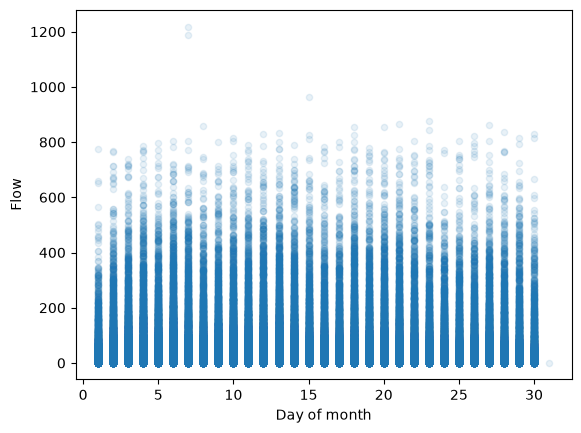

In [12]:
df_tramway_1_grouped_by_station_and_hour.plot(kind='scatter', x='Day of month', y='Flow', alpha=0.1)

On a deux valeurs de flows bizarres un mardi (le 7 janvier, mais qui correspond à un incendie qui a eu lieu à 12h30 ce même jour)  
https://france3-regions.franceinfo.fr/auvergne-rhone-alpes/rhone/lyon/lyon-camion-s-enflamme-cours-lafayette-perturbe-reseau-tcl-1771005.html

On retire la seule valeur de flow qui a été compté le 31 décembre car on n'a pas d'autres données pour le 31 janvier ou les autres stations => bug du comptage
Après vérification, il n'y a pas d'autre 31. Donc seulement 1 ligne.

In [13]:
df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['Day of month'] == 31]

,VAL_ARRET_CODE,VAL_DATE_Hour,CRS_SENS_TRAJET,Flow,Day of week,Day of month,Month,Hour,Is_workday,Is_holiday,Is_peak_hour
114884,34875,2019-12-31,2,1,1,31,12,0,1,0,0


In [14]:
df_tramway_1_grouped_by_station_and_hour.drop(df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['Day of month'] == 31].index, inplace=True)
df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['Day of month'] == 31]

C:\Users\chloe\AppData\Local\Temp\ipykernel_25840\2170719054.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_tramway_1_grouped_by_station_and_hour.drop(df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['Day of month'] == 31].index, inplace=True)


,VAL_ARRET_CODE,VAL_DATE_Hour,CRS_SENS_TRAJET,Flow,Day of week,Day of month,Month,Hour,Is_workday,Is_holiday,Is_peak_hour


### Station codes and remove unwanted stations

La ligne de T1 a 27 arrêts dans 1 sens donc 54 dans les deux sens.

In [15]:
list_arret_code = df_tramway_1_grouped_by_station_and_hour['VAL_ARRET_CODE'].unique()
list_arret_code

array([32102, 32103, 32104, 32105, 32106, 32107, 32108, 32109, 32110,
       32111, 32112, 32113, 32114, 32115, 32116, 32117, 32118, 32119,
       32120, 32121, 32122, 32123, 32124, 32125, 32126, 32127, 32128,
       32129, 32130, 32131, 32132, 32133, 32134, 32135, 32136, 32137,
       32138, 32139, 32141, 32143, 32147, 32161, 32163, 34067, 34068,
       34834, 34835, 34836, 34837, 34874, 34875, 35094, 45874, 46063,
       46154, 46155, 46156, 46157, 46158, 46159, 46160, 46161, 47290])

In [16]:
list_arret_code_ref = df_tramway_1.groupby('VAL_ARRET_CODE')['NOM_PNT'].first().to_dict()
list_arret_code_ref

{32102: 'Perrache',
 32103: 'Perrache.',
 32104: 'Quai Claude Bernard',
 32105: 'Quai Claude Bernard',
 32106: "Rue de l'Universite",
 32107: "Rue de l'Universite",
 32108: 'Saint-Andre',
 32109: 'Saint-Andre',
 32110: 'Guillotiere Gabriel Peri',
 32111: 'Guillotiere Gabriel Peri',
 32112: 'Liberte',
 32113: 'Liberte',
 32114: 'Saxe - Prefecture',
 32115: 'Saxe - Prefecture',
 32116: 'Palais de Justice',
 32117: 'Palais de Justice',
 32118: 'Part-Dieu Auditorium',
 32119: 'Part-Dieu Auditorium',
 32120: 'Gare Part-Dieu',
 32121: 'Gare  Part-Dieu',
 32122: 'Thiers - Lafayette',
 32123: 'Thiers - Lafayette',
 32124: 'College Bellecombe',
 32125: 'College Bellecombe',
 32126: 'Charpennes Charles Hernu',
 32127: 'Charpennes Charles Hernu',
 32128: 'Le Tonkin',
 32129: 'Le Tonkin',
 32130: 'Condorcet',
 32131: 'Condorcet',
 32132: 'Universite Lyon 1',
 32133: 'Universite Lyon 1',
 32134: 'La Doua - G.Berger',
 32135: 'La Doua - G.Berger',
 32136: 'INSA - Einstein',
 32137: 'INSA - Einstein'

In [17]:
df_tramway_1_grouped_by_station_and_hour
noms = df_tramway_1.groupby('VAL_ARRET_CODE')['NOM_PNT'].first()

# 1. Poids de chaque sens
print(df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'].value_counts())
print(df_tramway_1_grouped_by_station_and_hour.groupby('CRS_SENS_TRAJET')['Flow'].sum())

# 2. Pour chaque arrêt : combien de lignes dans chaque sens ?
ct = pd.crosstab(df_tramway_1_grouped_by_station_and_hour['VAL_ARRET_CODE'], df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'])
ct.insert(0, 'NOM', ct.index.map(noms))
print(ct.to_string())

# 3. Quels arrêts ont du sens 0 ?
print(ct[ct[0] > 0].sort_values(0, ascending=False))

CRS_SENS_TRAJET
1    65909
2    62943
0     7633
Name: count, dtype: int64
CRS_SENS_TRAJET
0     120275
1    4388636
2    4428659
Name: Flow, dtype: int64
CRS_SENS_TRAJET                       NOM     0     1     2
VAL_ARRET_CODE                                             
32102                            Perrache   196  2680     0
32103                           Perrache.   113     7  2699
32104                 Quai Claude Bernard   114     0  2601
32105                 Quai Claude Bernard   141  2490     0
32106                 Rue de l'Universite   106     0  2600
32107                 Rue de l'Universite   111  2578     0
32108                         Saint-Andre   105     0  2623
32109                         Saint-Andre    96  2539     0
32110            Guillotiere Gabriel Peri   112     0  2637
32111            Guillotiere Gabriel Peri   106  2617     0
32112                             Liberte   106     0  2550
32113                             Liberte   103  2523    32
32114

Cela montre que chaque station a bien 2 codes pour chaque sens (sens 1 et 2).
D'ailleurs, on voit que le sens 1 est IUT Feyssine vers Debourg
Le sens 2 est Debourg vers IUT Feyssine.

Sur le sens on a :
- Des arrêts qui ne sont pas sur la ligne T1 donc à enlever :
32141	Centre Berthelot
32143	Jean Mace
32147	Route de Vienne
32161	Desgenettes
32163	Essarts - Iris
47290	Challemel Lacour Artill.
- Des comptages sur chaque arrêts normaux (courses de début ou fin de service ?)
- Sur les terminus (retournement ?)
- Sur des arrêts particulier : Perrache, Arrière Gare Debourg et Feyssine



In [18]:
df_tramway_1_grouped_by_station_and_hour['Flow'].loc[df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'] == 0].sum()

np.int64(120275)

In [19]:
df_tramway_1_grouped_by_station_and_hour['Flow'].sum()

np.int64(8937570)

In [20]:
120275*100/8937570

1.3457237258001895

Le flux dans le sens 0, représente 1.3% du flux total.
Puisqu'on ne pas pas bien expliquer ces valeurs, nous décidons de les supprimer.

In [21]:
#J'enlève les stations qui ne sont pas sur la ligne T1
df_tramway_1_grouped_by_station_and_hour = df_tramway_1_grouped_by_station_and_hour[~df_tramway_1_grouped_by_station_and_hour['VAL_ARRET_CODE'].isin([32141, 32143, 32147, 32161, 32163, 47290])]

#Je garde seulement les sens 1 et 2
df_tramway_1_grouped_by_station_and_hour = df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'] != 0]

df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'].value_counts()
df_tramway_1_grouped_by_station_and_hour['VAL_ARRET_CODE'].nunique()

54

### Splitting the data

In [22]:
# Splitting it by direction
df_tramway_1_grouped_by_station_and_hour_direction_2 = df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'] == 2]
df_tramway_1_grouped_by_station_and_hour_direction_1 = df_tramway_1_grouped_by_station_and_hour[df_tramway_1_grouped_by_station_and_hour['CRS_SENS_TRAJET'] == 1]

df_tramway_1_grouped_by_station_and_hour_direction_2.to_csv(r'../Cleaned Data/tramway_1_direction_IUT_Feyssine_2.csv', index=False)
df_tramway_1_grouped_by_station_and_hour_direction_1.to_csv(r'../Cleaned Data/tramway_1_direction_Debourg_1.csv', index=False)


## Now for the weather data

**Links to understand data** :  
DOC POUR LES WEATHER CODES : https://www.historique-meteo.net/assets/docs/weathercodes.txt  
COLONNE OPINION : avis météo de 0 à 4 (0 = très défavorable • 1 = défavorable • 2 = mitigé • 3 = favorable • 4 = très favorable).

### Grouping data and removing unwanted columns

In [ ]:
df_weather_2019 = pd.read_csv(r'../Data/historique-meteo-lyon-2019.csv')
df_weather_2020 = pd.read_csv(r'../Data/historique-meteo-lyon-2020.csv')
df_weather_2020.head()

In [ ]:
df_weather = pd.concat([df_weather_2019, df_weather_2020])
df_weather.columns

In [ ]:
df_weather.drop(columns=['MAX_TEMPERATURE_C', 'MIN_TEMPERATURE_C', 'WINDSPEED_MAX_KMH','PRECIP_TOTAL_DAY_MM','HUMIDITY_MAX_PERCENT', 'VISIBILITY_AVG_KM', 'PRESSURE_MAX_MB',
       'CLOUDCOVER_AVG_PERCENT', 'HEATINDEX_MAX_C', 'DEWPOINT_MAX_C',
       'WINDTEMP_MAX_C','TOTAL_SNOW_MM','UV_INDEX','SUNHOUR',
       'OPINION', 'SUNSET', 'SUNRISE'], inplace=True)
df_weather.head()

### Making it fit the other dataset

In [ ]:
# That part was made using Claude. I provided the structure of my file and asked the code to make it like an example I provided. 
# Map each 6-hour period start to its temperature and weather code columns
period_map = {
    0:  ('TEMPERATURE_MIDNIGHT_0H',  'WEATHER_CODE_MIDNIGHT_0H'),
    6:  ('TEMPERATURE_MORNING_C_6H', 'WEATHER_CODE_MORNING_6H'),
    12: ('TEMPERATURE_NOON_C_12H',   'WEATHER_CODE_NOON_12H'),
    18: ('TEMPERATURE_EVENING_C_18H', 'WEATHER_CODE_EVENING_18H'),
}

daily = df_weather.copy()
daily['DATE'] = pd.to_datetime(daily['DATE'], format='%m-%d-%y')

# Long table: one row per (day, period) with Temperature and weather_code
parts = []
for hour, (t_col, w_col) in period_map.items():
    part = daily[['DATE', t_col, w_col]].copy()
    part.columns = ['DAY', 'Temperature', 'weather_code']
    part['PERIOD'] = hour
    parts.append(part)
values = pd.concat(parts, ignore_index=True)

# Every 15 minutes for every day in the data
times = pd.date_range(
    start=daily['DATE'].min(),
    end=daily['DATE'].max() + pd.Timedelta(hours=23, minutes=45),
    freq='15min',
)
out = pd.DataFrame({'VAL_DATE': times})
out['DAY'] = out['VAL_DATE'].dt.normalize()
out['PERIOD'] = out['VAL_DATE'].dt.hour // 6 * 6

out = out.merge(values, on=['DAY', 'PERIOD'], how='left')
out = out[['VAL_DATE', 'Temperature', 'weather_code']]

# Format dates like the example (11/2/19 15:00)
# On Linux/macOS use %-m and %-d; on Windows use %#m and %#d
out['VAL_DATE'] = out['VAL_DATE'].dt.strftime('%-m/%-d/%y %H:%M')
out.to_csv('../Data/weather_15min_2019_2020.csv', index=False)
print(out.shape)
print(out.head())

In [ ]:
df_weather_daily = out.copy()

### Replacing weather codes
So now, we are going to convert weather codes in ice(3)/snow(2)/rain(1)/no rain no snow(0). using the table weather-codes.csv

In [ ]:
weather_codes = pd.read_csv(r'../Cleaned Data/weather-codes.csv', index_col='WeatherCode')
weather_codes.columns


In [ ]:
df_weather_daily = df_weather_daily.merge(weather_codes, left_on='weather_code', right_index=True, how='left')
df_weather_daily.head()
df_weather_daily.to_csv(r'../Cleaned Data/weather_cleaned.csv',index=False)